In [13]:
# ==========================================
# STAGE 1: IMPORTS & SYSTEM SETUP
# ==========================================
import os
import wave
import time
import serial
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from scipy.signal import butter, lfilter
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Ensure your data directories exist cleanly
os.makedirs('data/good_bricks', exist_ok=True)
os.makedirs('data/bad_bricks', exist_ok=True)

# ==========================================
# STAGE 2: ESP32 USB AUDIO RECORDER
# ==========================================
COM_PORT = 'COM7' 
BAUD_RATE = 115200       # Match stable ESP32 firmware
SAMPLE_RATE = 8000       # Match the 1ms delay
RECORD_DURATION = 1.5  

def record_brick_sound(save_path):
    """Listens to stable ESP32 data stream and saves a WAV."""
    print(f"🔌 Connecting to ESP32 on {COM_PORT}...")
    try:
        ser = serial.Serial(COM_PORT, BAUD_RATE, timeout=1)
        time.sleep(2)
        ser.reset_input_buffer()
        
        print("Ready! Pull back the pendulum...")
        print("🔴 RECORDING STARTED! Strike the brick NOW!")
        
        audio_data = []
        total_samples = int(SAMPLE_RATE * RECORD_DURATION)
        max_attempts = total_samples * 3 
        attempts = 0
        
        while len(audio_data) < total_samples and attempts < max_attempts:
            attempts += 1
            line = ser.readline().decode('utf-8', errors='ignore').strip()
            if not line:
                continue
            try:
                clean_item = line.split()[0]
                clean_numeric = ''.join(c for c in clean_item if c.isdigit() or c in ['-', '+'])
                if clean_numeric:
                    val = int(clean_numeric)
                    if 0 <= val <= 4095:
                        normalized_val = int((val - 2048) * 16)
                        audio_data.append(normalized_val)
            except (ValueError, IndexError):
                continue
                    
        ser.close()
        
        if len(audio_data) == 0:
            print("❌ Error: Zero numeric entries captured.")
            return

        while len(audio_data) < total_samples:
            audio_data.append(0)

        audio_array = np.array(audio_data, dtype=np.int16)
        with wave.open(save_path, 'wb') as wf:
            wf.setnchannels(1)
            wf.setsampwidth(2)
            wf.setframerate(SAMPLE_RATE)
            wf.writeframes(audio_array.tobytes())
            
        print(f"✅ Successfully saved: {save_path}\n")
    except Exception as e:
        print(f"❌ Error: {e}.\n")

# ==========================================
# STAGE 3: DIGITAL SIGNAL PROCESSING (DSP)
# ==========================================
def butter_bandpass(lowcut, highcut, fs, order=3):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a

def apply_noise_filter(data, lowcut=20.0, highcut=3500.0, fs=8000, order=3):
    """Improved bandpass filter for brick acoustic analysis."""
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = lfilter(b, a, data)
    return y

def verify_signal_cleaning(file_path):
    """Visualizes the actual clean signals without erasing them via noise gates."""
    y, sr = librosa.load(file_path, sr=None)
    y = y - np.mean(y)
    y_clean = apply_noise_filter(y, fs=sr)

    plt.figure(figsize=(10, 4))
    plt.subplot(2, 1, 1)
    librosa.display.waveshow(y, sr=sr, color='gray', alpha=0.6)
    plt.title("Raw Audio")
    
    plt.subplot(2, 1, 2)
    librosa.display.waveshow(y_clean, sr=sr, color='teal')
    plt.title("Filtered Audio (Preserved Ring)")
    plt.tight_layout()
    plt.show()

# ==========================================
# STAGE 4: FEATURE EXTRACTION & AI TRAINING
# ==========================================
def extract_acoustic_features(file_path):

    y, sr = librosa.load(file_path, sr=48000)

    # Remove DC offset
    y = y - np.mean(y)

    # Apply filtering
    y_clean = apply_noise_filter(y, fs=sr)

    # Normalize safely
    if np.max(np.abs(y_clean)) != 0:
        y_clean = y_clean / np.max(np.abs(y_clean))

    # FFT
    fft = np.abs(np.fft.rfft(y_clean))
    freqs = np.fft.rfftfreq(len(y_clean), 1/sr)

    # Peak frequency
    peak_freq = freqs[np.argmax(fft)]

    # Peak magnitude
    peak_magnitude = np.max(fft)

    # RMS energy
    rms_energy = np.sqrt(np.mean(y_clean**2))

    # Zero crossing rate
    zero_crossings = np.mean(librosa.zero_crossings(y_clean))

    # Spectral centroid
    spectral_centroid = np.mean(
        librosa.feature.spectral_centroid(y=y_clean, sr=sr)
    )

    # Feature vector
    features = np.array([
        peak_freq,
        peak_magnitude,
        rms_energy,
        zero_crossings,
        spectral_centroid
    ])

    return features

def train_brick_classifier():
    X, y = [], []
    categories = {'data/bad_bricks': 0, 'data/good_bricks': 1}
    
    print("📦 Processing recorded acoustic data...")
    for folder, label in categories.items():
        if not os.path.exists(folder): continue
        for file in os.listdir(folder):
            if file.endswith('.wav'):
                file_path = os.path.join(folder, file)
                try:
                    features = extract_acoustic_features(file_path)
                    X.append(features)
                    y.append(label)
                except Exception as e:
                    print(f"⚠️ Skipped file {file}: {e}")

    if len(X) == 0:
        print("❌ Dataset is empty!")
        return None

    X, y = np.array(X), np.array(y)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

    print(f"🌲 Training Random Forest Classifier on {len(X_train)} samples...")
    model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)
    model.fit(X_train, y_train)
    print("🎯 Training Complete!")

    y_pred = model.predict(X_test)
    print("\n========= CLASSIFICATION REPORT =========")
    print(classification_report(y_test, y_pred,target_names=['Bad Brick', 'Good Brick']))
    
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Bad Brick', 'Good Brick'])
    disp.plot(cmap=plt.cm.Blues)
    plt.title("Model Validation: Real Brick Confusion Matrix")
    plt.show()
    return model


def compare_fft(file1, file2):

    y1, sr1 = librosa.load(file1, sr=None)
    y2, sr2 = librosa.load(file2, sr=None)

    y1 = apply_noise_filter(y1, fs=sr1)
    y2 = apply_noise_filter(y2, fs=sr2)

    fft1 = np.abs(np.fft.rfft(y1))
    fft2 = np.abs(np.fft.rfft(y2))

    freqs1 = np.fft.rfftfreq(len(y1), 1/sr1)
    freqs2 = np.fft.rfftfreq(len(y2), 1/sr2)

    plt.figure(figsize=(10,5))

    plt.plot(freqs1, fft1, label='Good Brick')
    plt.plot(freqs2, fft2, label='Bad Brick')

    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Magnitude")
    plt.title("FFT Comparison")
    plt.legend()

    plt.show()

In [18]:
def predict_brick(file_path, model):

    features = extract_acoustic_features(file_path)

    prediction = model.predict([features])[0]

    confidence = max(model.predict_proba([features])[0]) * 100

    if prediction == 1:
        print(f"GOOD BRICK ({confidence:.2f}%)")
    else:
        print(f"BAD BRICK ({confidence:.2f}%)")

    return prediction, confidence

In [19]:
predict_brick("data/test_bricks/btestdiff.wav", brick_model)

GOOD BRICK (60.00%)


(np.int64(1), np.float64(60.0))

📦 Processing recorded acoustic data...
🌲 Training Random Forest Classifier on 45 samples...
🎯 Training Complete!

========= CLASSIFICATION REPORT =========
              precision    recall  f1-score   support

   Bad Brick       1.00      0.60      0.75         5
  Good Brick       0.78      1.00      0.88         7

    accuracy                           0.83        12
   macro avg       0.89      0.80      0.81        12
weighted avg       0.87      0.83      0.82        12



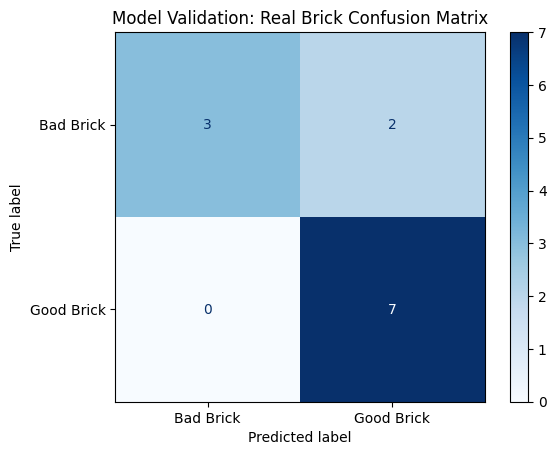

In [20]:
brick_model = train_brick_classifier()

In [21]:
import pickle

with open("brick_model.pkl", "wb") as f:
    pickle.dump(brick_model, f)

print("Model Saved")

Model Saved


In [22]:
import joblib

loaded_model = joblib.load("brick_model.pkl")

print("Loaded Successfully")

Loaded Successfully


In [23]:
import joblib

joblib.dump(brick_model, "brick_model.pkl")

print("✅ Model Saved")

✅ Model Saved
